# 04 · Optimización y contraste con Semana 5

Resultados reales disponibles de tres configuraciones. Este notebook no transforma 100 épocas en 100 ensayos independientes ni atribuye una búsqueda Optuna que no se ha realizado.

In [1]:
from pathlib import Path
import sys, json, csv, hashlib
from html import escape
from IPython.display import display, Markdown, HTML, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/paths.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
def load(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))
def table(rows):
    if not rows:
        return display(Markdown("Sin filas."))
    keys = list(rows[0])
    head = "".join("<th>" + escape(str(k)) + "</th>" for k in keys)
    body = "".join("<tr>" + "".join("<td>" + escape(str(r.get(k, ""))) + "</td>" for k in keys) + "</tr>" for r in rows)
    display(HTML("<table><thead><tr>"+head+"</tr></thead><tbody>"+body+"</tbody></table>"))
print("Raíz del proyecto localizada. Se utilizan evidencias reales del repositorio.")


Raíz del proyecto localizada. Se utilizan evidencias reales del repositorio.


In [2]:
from src.comparar_experimentos import main as comparar
comparar()
report=load("results/metrics/comparacion_experimentos.json")
table([{k:r[k] for k in ["experiment","weight_decay","degrees","best_logged_epoch","map50_95","improvement_over_baseline_pp"]} for r in report["experiments"]])

{"experiment": "yolov9t_baseline", "epochs": 100, "weight_decay": 0.0005, "degrees": 0.0, "best_logged_epoch": 80, "precision": 0.97499, "recall": 0.97314, "map50": 0.98289, "map50_95": 0.88673, "last_map50_95": 0.88078, "recorded_training_minutes": 87.18966666666667, "reevaluated_best_epoch": 78, "reevaluated_val_map50_95": 0.8869937846554071, "reevaluated_train_map50_95": 0.926800569152158, "reevaluated_gap_pp": 3.98067844967509, "improvement_over_baseline_pp": 0.0}
{"experiment": "yolov9t_regularizacion", "epochs": 100, "weight_decay": 0.001, "degrees": 0.0, "best_logged_epoch": 82, "precision": 0.97822, "recall": 0.96825, "map50": 0.98242, "map50_95": 0.89057, "last_map50_95": 0.88368, "recorded_training_minutes": 73.05216666666666, "reevaluated_best_epoch": 84, "reevaluated_val_map50_95": 0.8901742933474285, "reevaluated_train_map50_95": 0.9301414774092223, "reevaluated_gap_pp": 3.996718406179378, "improvement_over_baseline_pp": 0.38399999999999546}
{"experiment": "yolov9t_rotacio

experiment,weight_decay,degrees,best_logged_epoch,map50_95,improvement_over_baseline_pp
yolov9t_baseline,0.0005,0.0,80,0.88673,0.0
yolov9t_regularizacion,0.001,0.0,82,0.89057,0.38399999999999546
yolov9t_rotacion,0.0005,5.0,89,0.88884,0.21099999999999453


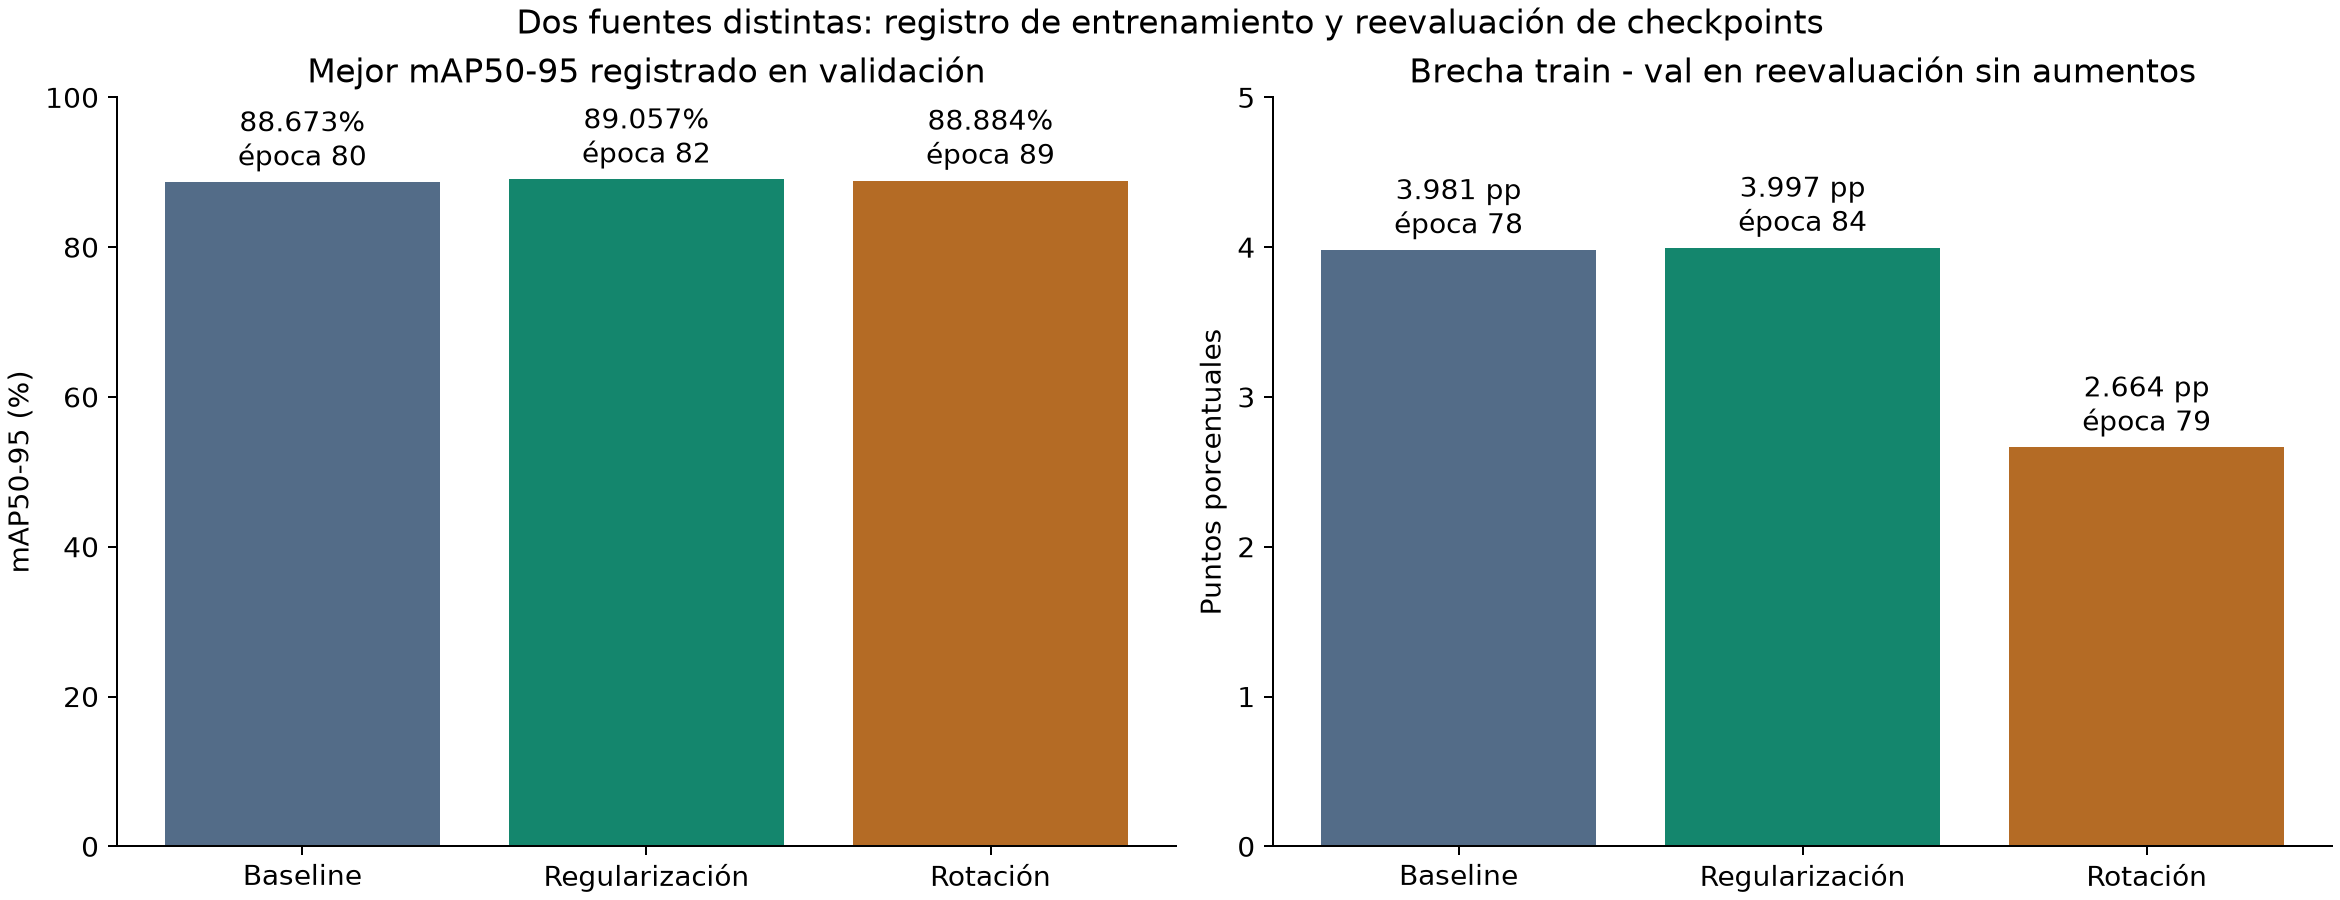

In [3]:
display(Image(filename=str(ROOT/"results/figures/comparacion_modelos.png"),width=1000))

## Interpretación

La regularización aumenta mAP50–95 de validación en 0,384 puntos porcentuales. Una corrida por configuración no establece significancia. La rotación reduce la brecha train/val en las épocas reevaluadas, sin obtener el máximo mAP50–95. No se utiliza test para seleccionar hiperparámetros.

In [4]:
import itertools
observed={(r["weight_decay"],r["degrees"]) for r in report["experiments"]}
grid=set(itertools.product([0.0005,0.001],[0.0,5.0]))
print("Combinaciones observadas:",sorted(observed))
print("Combinación ausente:",sorted(grid-observed))
print("No se ajusta un sustituto con tres observaciones ni se fabrican PDP/interacciones.")

Combinaciones observadas: [(0.0005, 0.0), (0.0005, 5.0), (0.001, 0.0)]
Combinación ausente: [(0.001, 5.0)]
No se ajusta un sustituto con tres observaciones ni se fabrican PDP/interacciones.


## Qué pide el material recibido

`Semana5_Workshops_semana5 (1).ipynb` contiene estrés controlado y 60 ensayos Optuna en Random Forest, importancia, slice/contorno, dependencia parcial mediante un sustituto y evaluación final separada. Adaptar ese método al detector exige nuevos experimentos o un estudio de inferencia claramente separado del entrenamiento. Está pendiente; este notebook no cierra ese requisito. Véase `docs/semana5_brechas.md`.